In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

In [2]:
# Вспомогательная функция для вычисления радиальной части полиномов Цернике
def R(n, m, r):
    """Функция для расчета радиальной части полинома Цернике"""
    if (n - m) % 2 != 0:
        return np.zeros_like(r)  # Если разность нечетная, результат 0

    radial_sum = np.zeros_like(r)
    for k in range((n - m) // 2 + 1):
        c = (-1) ** k * factorial(n - k) / (factorial(k) * factorial((n + m) // 2 - k) * factorial((n - m) // 2 - k))
        radial_sum += c * r ** (n - 2 * k)
    return radial_sum

In [3]:
# Функция для обрезки изображения до центральной части 128x128
def crop_center(img, crop_size=128):
    h, w = img.shape
    startx = w // 2 - (crop_size // 2)
    starty = h // 2 - (crop_size // 2)    
    return img[starty:starty + crop_size, startx:startx + crop_size]

In [4]:

# Основная функция для вычисления полиномов Цернике
def zernike_polynomial(n, m, rho, theta):
    """
    Вычисление полинома Цернике.
    n - радиальный порядок
    m - азимутальный порядок
    rho - радиальная координата (от 0 до 1)
    theta - угловая координата (от 0 до 2pi)
    """
    if m >= 0:
        return R(n, m, rho) * np.cos(m * theta)
    else:
        return R(n, -m, rho) * np.sin(-m * theta)




# Пример визуализации полинома Цернике
def plot_zernike(n, m, a, b, grid_size=100):
    """Визуализация полинома Цернике с порядками n и m"""
    y, x = np.linspace(-1, 1, grid_size), np.linspace(-1, 1, grid_size)
    X, Y = np.meshgrid(x, y)
    rho = np.sqrt(X**2 + Y**2)
    theta = np.arctan2(Y, X)
    
    # Ограничиваем область единичным кругом
    mask = rho <= 1
    rho[~mask] = 0
    theta[~mask] = 0
    
    Z = zernike_polynomial(n, m, rho, theta)
    Z1 = np.exp(1j * a * Z)

    R = np.sqrt(X ** 2 + Y ** 2)

    axc = np.cos(b * R)

    Z1_temp = np.exp(1j * np.angle(axc)) * Z1 
    Z1a = np.cos( (a * Z + b * R))
    # Z1a = np.exp(1j * (a * Z + b * np.sqrt(X ** 2 + Y ** 2)))

    Zf = np.fft.fftshift(np.fft.fft2(Z, s=[1000, 1000]))

    Z1f = np.fft.fftshift(np.fft.fft2(Z1, s=[1000, 1000]))

    Z1af = np.fft.fftshift(np.fft.fft2(Z1_temp, s=[512, 512]))

  # Создание сетки 2x2 для отображения графиков
    fig, axs = plt.subplots(2, 2, figsize=(12, 12))

    # # График 1: Исходный полином Цернике
    #img1 = plt.imshow(Z, extent=(-1, 1, -1, 1), cmap='RdBu')

    # График 1: Фаза исходного поля

    # img1 = axs[0, 0].imshow(abs(Z), extent=(-1, 1, -1, 1), cmap='RdBu')
    # axs[0, 0].set_title(f"Zernike Polynomial (n={n}, m={m})")
    # plt.colorbar(img1, ax=axs[0, 0])

    # # График 2: Фурье-преобразование исходного полинома
    # img2 = axs[0, 1].imshow(abs(Zf), extent=(-1, 1, -1, 1), cmap='grey')
    # axs[0, 1].set_title(f"Zernike Polynomial amplitude (n={n}, m={m})")
    # plt.colorbar(img2, ax=axs[0, 1])

        # График 3: Фазовая картина с наложением аксикона
    img3 = axs[0, 0].imshow(np.angle(Z1), extent=(-1, 1, -1, 1), cmap='grey')
    axs[0, 0].set_title(f"Zernike Polynomial phase (n={n}, m={m}, b=0)")
    plt.colorbar(img3, ax=axs[0, 0])

        # График 3: Фазовая картина с наложением аксикона
    img4 = axs[0, 1].imshow(abs(Z1f), extent=(-1, 1, -1, 1), cmap='grey')
    axs[0, 1].set_title(f"Zernike Polynomial phase amplitude (n={n}, m={m}, b=0)")
    plt.colorbar(img4, ax=axs[0, 1])

    # График 3: Фазовая картина с наложением аксикона
    img3 = axs[1, 0].imshow(np.angle(Z1a), extent=(-1, 1, -1, 1), cmap='grey')
    axs[1, 0].set_title(f"Zernike Polynomial phase (n={n}, m={m}, b={b})")
    plt.colorbar(img3, ax=axs[1, 0])

        # График 3: Фазовая картина с наложением аксикона
    img4 = axs[1, 1].imshow(abs(Z1af), extent=(-1, 1, -1, 1), cmap='grey')
    axs[1, 1].set_title(f"Zernike Polynomial phase amplitude (n={n}, m={m}, b={b})")
    plt.colorbar(img4, ax=axs[1, 1])

    plt.imsave(f'TestImages/zernike_aberration_n{n}_m{m}_a{a:.2f}_b{b:.2f}_aug.png', crop_center(abs(Z1af)), cmap='gray')

    # Отображаем графики
    plt.tight_layout()
    plt.show()



In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Бяка с дробями в экспоненте (Гаус-Л) m - int
def multi_channel_filter(n,m,a, Sg, C, grid_size=100):
    y, x = np.linspace(-1, 1, grid_size), np.linspace(-1, 1, grid_size)
    #alph = [10, 15, 20, 25]
    Ln = [0, 1, 5, 7]

    X, Y = np.meshgrid(x, y)
    R = np.sqrt(X ** 2 + Y ** 2)

    # Исправлено: правильное вычисление комплексной экспоненты
    # Каждый член должен быть exp(1j * C * X + 1j * C * Y) или аналогично

    Gs = np.exp(-(R ** 2) / (Sg ** 2)) 
              


    Fl = ((X + 1j * Y) ** (Ln[0]) * (Ln[1]) * np.exp(1j * C * X + 1j * C * Y) + 
          (X + 1j * Y) ** (Ln[1]) * (Ln[1]) *np.exp(1j * (-C) * X + 1j * C * Y) + 
          (X + 1j * Y) ** (Ln[2]) * (Ln[2]) *np.exp(1j * C * X + 1j * (-C) * Y) + 
          (X + 1j * Y) ** (Ln[3]) * (Ln[3]) *np.exp(1j * (-C) * X + 1j * (-C) * Y))
    
    rho = np.sqrt(X**2 + Y**2)
    theta = np.arctan2(Y, X)
    
    # Ограничиваем область единичным кругом
    mask = rho <= 1
    rho[~mask] = 0
    theta[~mask] = 0
    
    Z = zernike_polynomial(n, m, rho, theta)
    Z1 = np.exp(1j * a * Z)
    Fl = Fl * Z1 * Gs

    Flf = np.fft.fftshift(np.fft.fft2(Fl, s=[1000, 1000]))

    # Создание одного графика (не сетки)
    fig, ax = plt.subplots(1, 1, figsize=(8, 6))

    # Исправлено: ax - это одиночный объект Axes, а не массив
    img3 = ax.imshow(np.abs(Flf), extent=(-1, 1, -1, 1), cmap='grey')
    ax.set_title(f"MultiChannel Filter (C={C})")
    plt.colorbar(img3, ax=ax)
    plt.show()
    
    return Flf
# добавить церинке алгоритм, аксикон убрать alph = b заменить
# 1 сравнить многоканал и одноканал
# 2 многоканалка прогнать на разных архитектурах

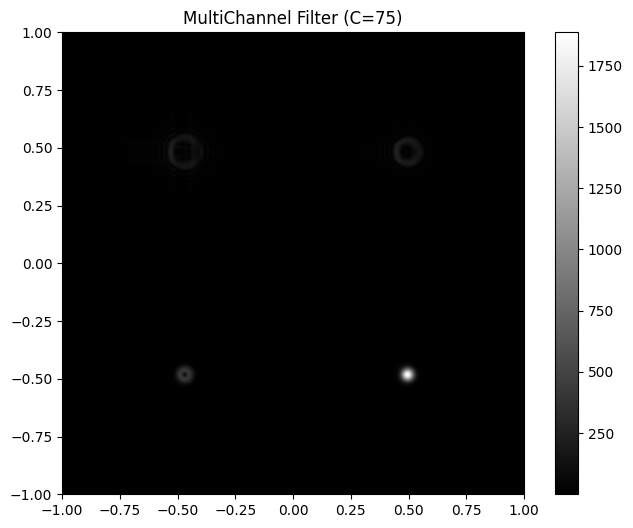

In [6]:
#            n  m  a   b
# plot_zernike(1, 1, 2, 5)
# Пример использования
#(n,m,a, Sg, C, grid_size=100 #n  m  a  Sg C  
result = multi_channel_filter(1, 1, 2, 0.5, 75)

In [7]:
import numpy as np
import matplotlib.pyplot as plt
# Аксикон (Бесселев пучок)
def multi_channel_filter_ax(n,m,a, C, grid_size=100):
    y, x = np.linspace(-1, 1, grid_size), np.linspace(-1, 1, grid_size)
    # аксикон
    alph = [10, 15, 20, 30]

    X, Y = np.meshgrid(x, y)
    R = np.sqrt(X ** 2 + Y ** 2)

    # Исправлено: правильное вычисление комплексной экспоненты
    # Каждый член должен быть exp(1j * C * X + 1j * C * Y) или аналогично
    Fl = (np.exp(1j * alph[0] * R) * np.exp(1j * C * X + 1j * C * Y) + 
          np.exp(1j * alph[1] * R) * np.exp(1j * (-C) * X + 1j * C * Y) + 
          np.exp(1j * alph[2] * R) * np.exp(1j * C * X + 1j * (-C) * Y) + 
          np.exp(1j * alph[3] * R) * np.exp(1j * (-C) * X + 1j * (-C) * Y))
    
    rho = np.sqrt(X**2 + Y**2)
    theta = np.arctan2(Y, X)
    
    # Ограничиваем область единичным кругом
    mask = rho <= 1
    rho[~mask] = 0
    theta[~mask] = 0
    
    Z = zernike_polynomial(n, m, rho, theta)
    Z1 = np.exp(1j * a * Z)
    Fl = Fl * Z1

    Flf = np.fft.fftshift(np.fft.fft2(Fl, s=[1000, 1000]))

    # Создание одного графика (не сетки)
    fig, ax = plt.subplots(1, 1, figsize=(8, 6))

    # Исправлено: ax - это одиночный объект Axes, а не массив
    img3 = ax.imshow(np.abs(Flf), extent=(-1, 1, -1, 1), cmap='RdBu')
    ax.set_title(f"MultiChannel Filter (C={C})")
    plt.colorbar(img3, ax=ax)
    plt.show()
    
    return Flf
# добавить церинке алгоритм, аксикон убрать alph = b заменить
# 1 сравнить многоканал и одноканал
# 2 многоканалка прогнать на разных архитектурах

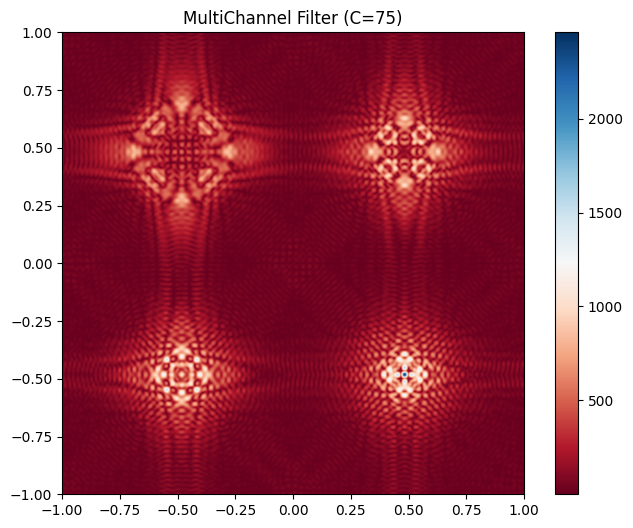

In [8]:
result = multi_channel_filter_ax(4, 4, 10, 75)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

def visualize_dataset_image(n, m, a, C=75, grid_size=100, fft_size=1000):
    """
    Точная визуализация изображения, как оно сохраняется в датасете.
    """
    # === ТОЧНОЕ КОПИРОВАНИЕ ЛОГИКИ generate_images ===
    y, x = np.linspace(-1, 1, grid_size), np.linspace(-1, 1, grid_size)
    alph = [10, 15, 20, 30]
    X, Y = np.meshgrid(x, y)
    R = np.sqrt(X**2 + Y**2)
    theta = np.arctan2(Y, X)
    
    mask = R <= 1
    R[~mask] = 0
    theta[~mask] = 0

    # Мультиканальное поле
    Fl = (np.exp(1j * alph[0] * R) * np.exp(1j * C * X + 1j * C * Y) + 
          np.exp(1j * alph[1] * R) * np.exp(1j * (-C) * X + 1j * C * Y) + 
          np.exp(1j * alph[2] * R) * np.exp(1j * C * X + 1j * (-C) * Y) + 
          np.exp(1j * alph[3] * R) * np.exp(1j * (-C) * X + 1j * (-C) * Y))
    
    # Полином Цернике
    Z = zernike_polynomial(n, m, R, theta)
    Z1 = np.exp(1j * a * Z)
    Fl = Fl * Z1
    
    # FFT с тем же размером, что и в датасете
    Flf = np.fft.fftshift(np.fft.fft2(Fl, s=[fft_size, fft_size]))
    aberration_img = np.abs(Flf) 
    
    # === ВИЗУАЛИЗАЦИЯ ===
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    
    # 1. Фаза аберрации Цернике (только для иллюстрации)
    phase_img = np.angle(np.exp(1j * a * Z))
    plt.imsave(os.path.join('phases', f'Фаза аберрации_n{n}_m{m}_a{a:.2f}.png'), phase_img,cmap='gray')
    img1 = axs[0].imshow(phase_img, extent=(-1, 1, -1, 1), cmap='gray')
    axs[0].set_title(f'Фаза аберрации (n={n}, m={m}, a={a})')
    plt.colorbar(img1, ax=axs[0])
    
    # 2. Точная копия изображения из датасета
    plt.imsave(os.path.join('aberrs', f'Изображение из датасета_n{n}_m{m}_a{a:.2f}.png'), aberration_img,cmap='gray')
    img2 = axs[1].imshow(aberration_img, cmap='gray')
    axs[1].set_title(f'Изображение из датасета (FFT {fft_size}×{fft_size})')
    axs[1].axis('off')  # как при plt.imsave
    
    plt.tight_layout()
    plt.show()
    
    return aberration_img  # можно сохранить как в датасете

# Пример использования:
# img = visualize_dataset_image(n=2, m=2, a=5.0, C=75)
# plt.imsave('test.png', img, cmap='gray')  # ← будет идентично датасету!

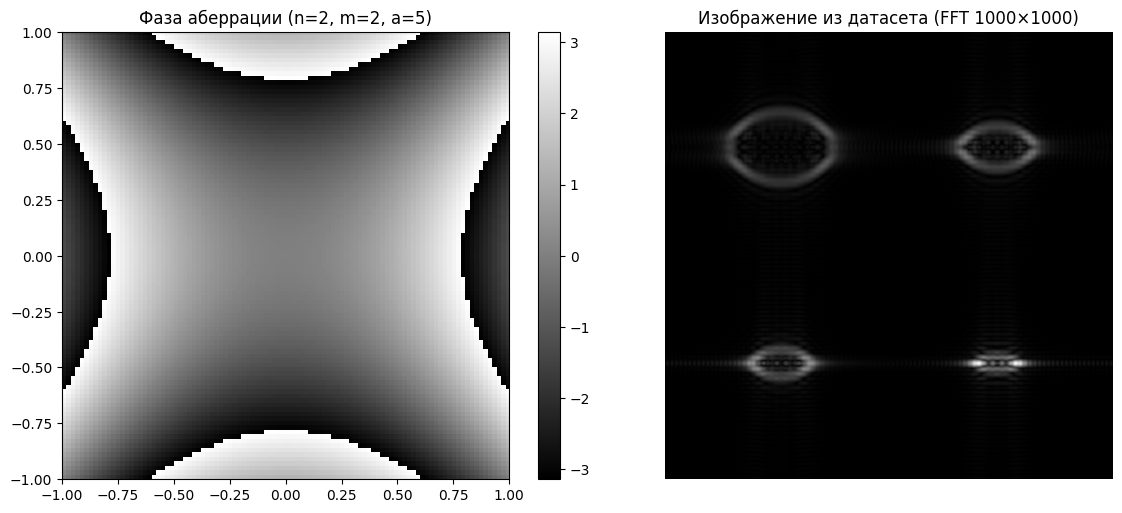

In [16]:
result = visualize_dataset_image(2, 2, 5, 75)
